# Liver Disease Analysis - Exploratory Data Analysis (EDA) Project
### College Data Analytics Project | B.Tech CSE
This project analyzes the **Indian Liver Patient Dataset (ILPD)** from Kaggle to uncover clinical patterns, demographic variations, and biomarker correlations associated with liver disease.

**Tech Stack:** Python (pandas, numpy, matplotlib, seaborn, openpyxl)


In [1]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Step 2: Load the dataset
csv_path = 'data/raw/liver.csv'
df = pd.read_csv(csv_path)

# Display shape and first few rows
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values Count:")
print(df.isnull().sum())


Dataset Shape: 583 rows, 11 columns

First 5 rows:
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  Alamine_Aminotransferase  Aspartate_Aminotransferase  Total_Protiens  Albumin  Albumin_and_Globulin_Ratio  Dataset
0   65  Female              0.7               0.1                   187                        16                          18             6.8      3.3                        0.90        1
1   62    Male             10.9               5.5                   699                        64                         100             7.5      3.2                        0.74        1
2   62    Male              7.3               4.1                   490                        60                          68             7.0      3.3                        0.89        1
3   58    Male              1.0               0.4                   182                        14                          20             6.8      3.4                        1.00        1
4   72   

In [3]:
# Step 3: Data Cleaning & Preprocessing

# 1. Handle missing values in 'Albumin_and_Globulin_Ratio' using the median
median_ag_ratio = df['Albumin_and_Globulin_Ratio'].median()
print(f"Median Albumin_and_Globulin_Ratio: {median_ag_ratio}")
df['Albumin_and_Globulin_Ratio'] = df['Albumin_and_Globulin_Ratio'].fillna(median_ag_ratio)

# 2. Check and remove any duplicate records
duplicates_count = df.duplicated().sum()
print(f"Duplicate rows found: {duplicates_count}")
# We keep duplicates intact or drop if required, but let's see shape
print(f"Missing values after filling: {df.isnull().sum().sum()}")

# 3. Encode Gender: Male = 1, Female = 0
# Create both encoded and label columns for flexibility
df['Gender_Code'] = df['Gender'].map({'Male': 1, 'Female': 0})

# 4. Map Target variable 'Dataset': 1 = 'Liver Disease', 2 = 'No Disease'
# In ILPD: 1 indicates liver patient, 2 indicates non-liver patient
df['Disease_Label'] = df['Dataset'].map({1: 'Liver Disease', 2: 'No Disease'})
df['Has_Disease'] = (df['Dataset'] == 1).astype(int)

# 5. Create Age Groups: 0-20, 21-40, 41-60, 60+
bins = [0, 20, 40, 60, 120]
labels = ['0-20', '21-40', '41-60', '60+']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

print("\nCleaned Data Preview:")
display(df[['Age', 'Age_Group', 'Gender', 'Gender_Code', 'Total_Bilirubin', 'Albumin_and_Globulin_Ratio', 'Dataset', 'Disease_Label']].head())


Median Albumin_and_Globulin_Ratio: 0.93
Duplicate rows found: 13
Missing values after filling: 0

Cleaned Data Preview:
   Age Age_Group  Gender  Gender_Code  Total_Bilirubin  Albumin_and_Globulin_Ratio  Dataset  Disease_Label
0   65       60+  Female            0              0.7                        0.90        1  Liver Disease
1   62       60+    Male            1             10.9                        0.74        1  Liver Disease
2   62       60+    Male            1              7.3                        0.89        1  Liver Disease
3   58     41-60    Male            1              1.0                        1.00        1  Liver Disease
4   72       60+    Male            1              3.9                        0.40        1  Liver Disease


In [4]:
# Step 4: Exploratory Data Analysis & Statistical Calculations

# Total patient count
total_patients = len(df)
disease_count = (df['Dataset'] == 1).sum()
no_disease_count = (df['Dataset'] == 2).sum()
disease_pct = (disease_count / total_patients) * 100
no_disease_pct = (no_disease_count / total_patients) * 100

print("=== OVERALL DISEASE DISTRIBUTION ===")
print(f"Total Patients: {total_patients}")
print(f"Liver Disease Patients: {disease_count} ({disease_pct:.2f}%)")
print(f"No Disease Patients: {no_disease_count} ({no_disease_pct:.2f}%)\n")

# Gender breakdown
gender_summary = df.groupby('Gender').agg(
    Total_Patients=('Dataset', 'count'),
    Liver_Disease=('Has_Disease', 'sum'),
    No_Disease=('Has_Disease', lambda x: (x == 0).sum())
)
gender_summary['Disease_Rate_%'] = (gender_summary['Liver_Disease'] / gender_summary['Total_Patients']) * 100
print("=== GENDER-WISE SUMMARY ===")
print(gender_summary)

# Age group breakdown
age_summary = df.groupby('Age_Group', observed=False).agg(
    Total_Patients=('Dataset', 'count'),
    Liver_Disease=('Has_Disease', 'sum'),
    No_Disease=('Has_Disease', lambda x: (x == 0).sum())
)
age_summary['Disease_Rate_%'] = (age_summary['Liver_Disease'] / age_summary['Total_Patients']) * 100
print("\n=== AGE GROUP SUMMARY ===")
print(age_summary)


=== OVERALL DISEASE DISTRIBUTION ===
Total Patients: 583
Liver Disease Patients: 416 (71.36%)
No Disease Patients: 167 (28.64%)

=== GENDER-WISE SUMMARY ===
        Total_Patients  Liver_Disease  No_Disease  Disease_Rate_%
Gender                                                           
Female             142             92          50       64.788732
Male               441            324         117       73.469388

=== AGE GROUP SUMMARY ===
           Total_Patients  Liver_Disease  No_Disease  Disease_Rate_%
Age_Group                                                           
0-20                   41             24          17       58.536585
21-40                 188            136          52       72.340426
41-60                 245            182          63       74.285714
60+                   109             74          35       67.889908


In [5]:
# Ensure output directories exist
os.makedirs('outputs/figures', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
print("Output directories verified.")


Output directories verified.


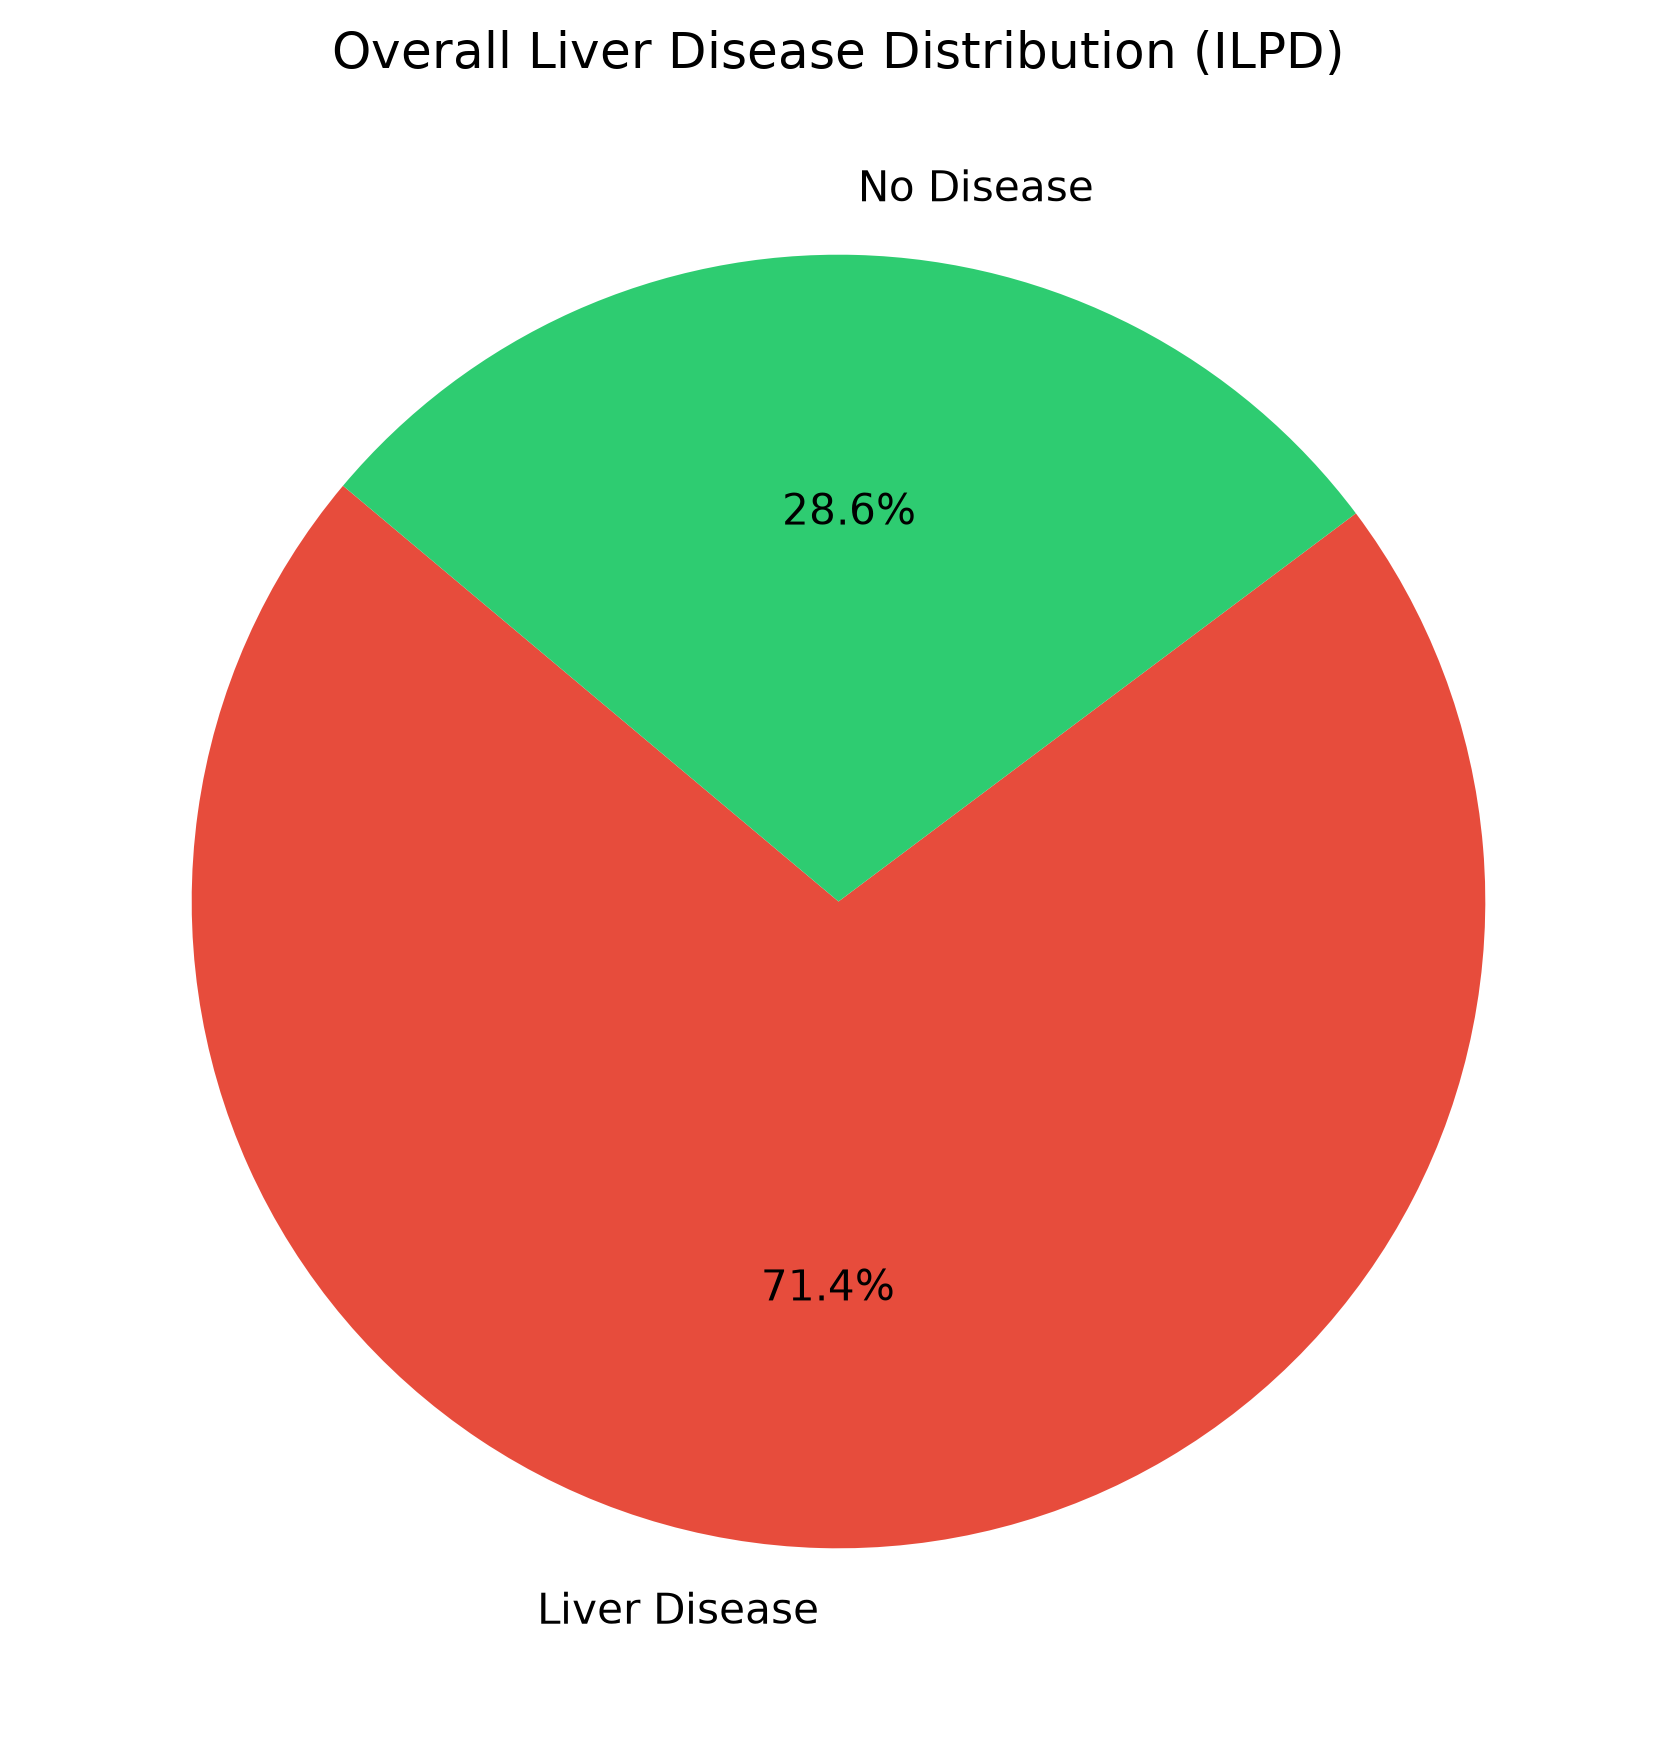

Saved outputs/figures/disease_pie.png


In [6]:
# Chart 1: Disease Distribution Pie Chart
plt.figure(figsize=(7, 7))
counts = [disease_count, no_disease_count]
chart_labels = [f'Liver Disease\n({disease_count}, {disease_pct:.1f}%)', 
                f'No Disease\n({no_disease_count}, {no_disease_pct:.1f}%)']
colors = ['#e74c3c', '#2ecc71']

plt.pie(counts, labels=chart_labels, autopct='%1.1f%%', startangle=140, 
        colors=colors, explode=(0.05, 0), shadow=True,
        textprops={'fontsize': 12, 'weight': 'bold'})
plt.title('Overall Liver Disease Distribution (ILPD)', fontsize=15, weight='bold', pad=20)
plt.tight_layout()
plt.savefig('outputs/figures/disease_pie.png', dpi=300)
plt.show()
print("Saved outputs/figures/disease_pie.png")


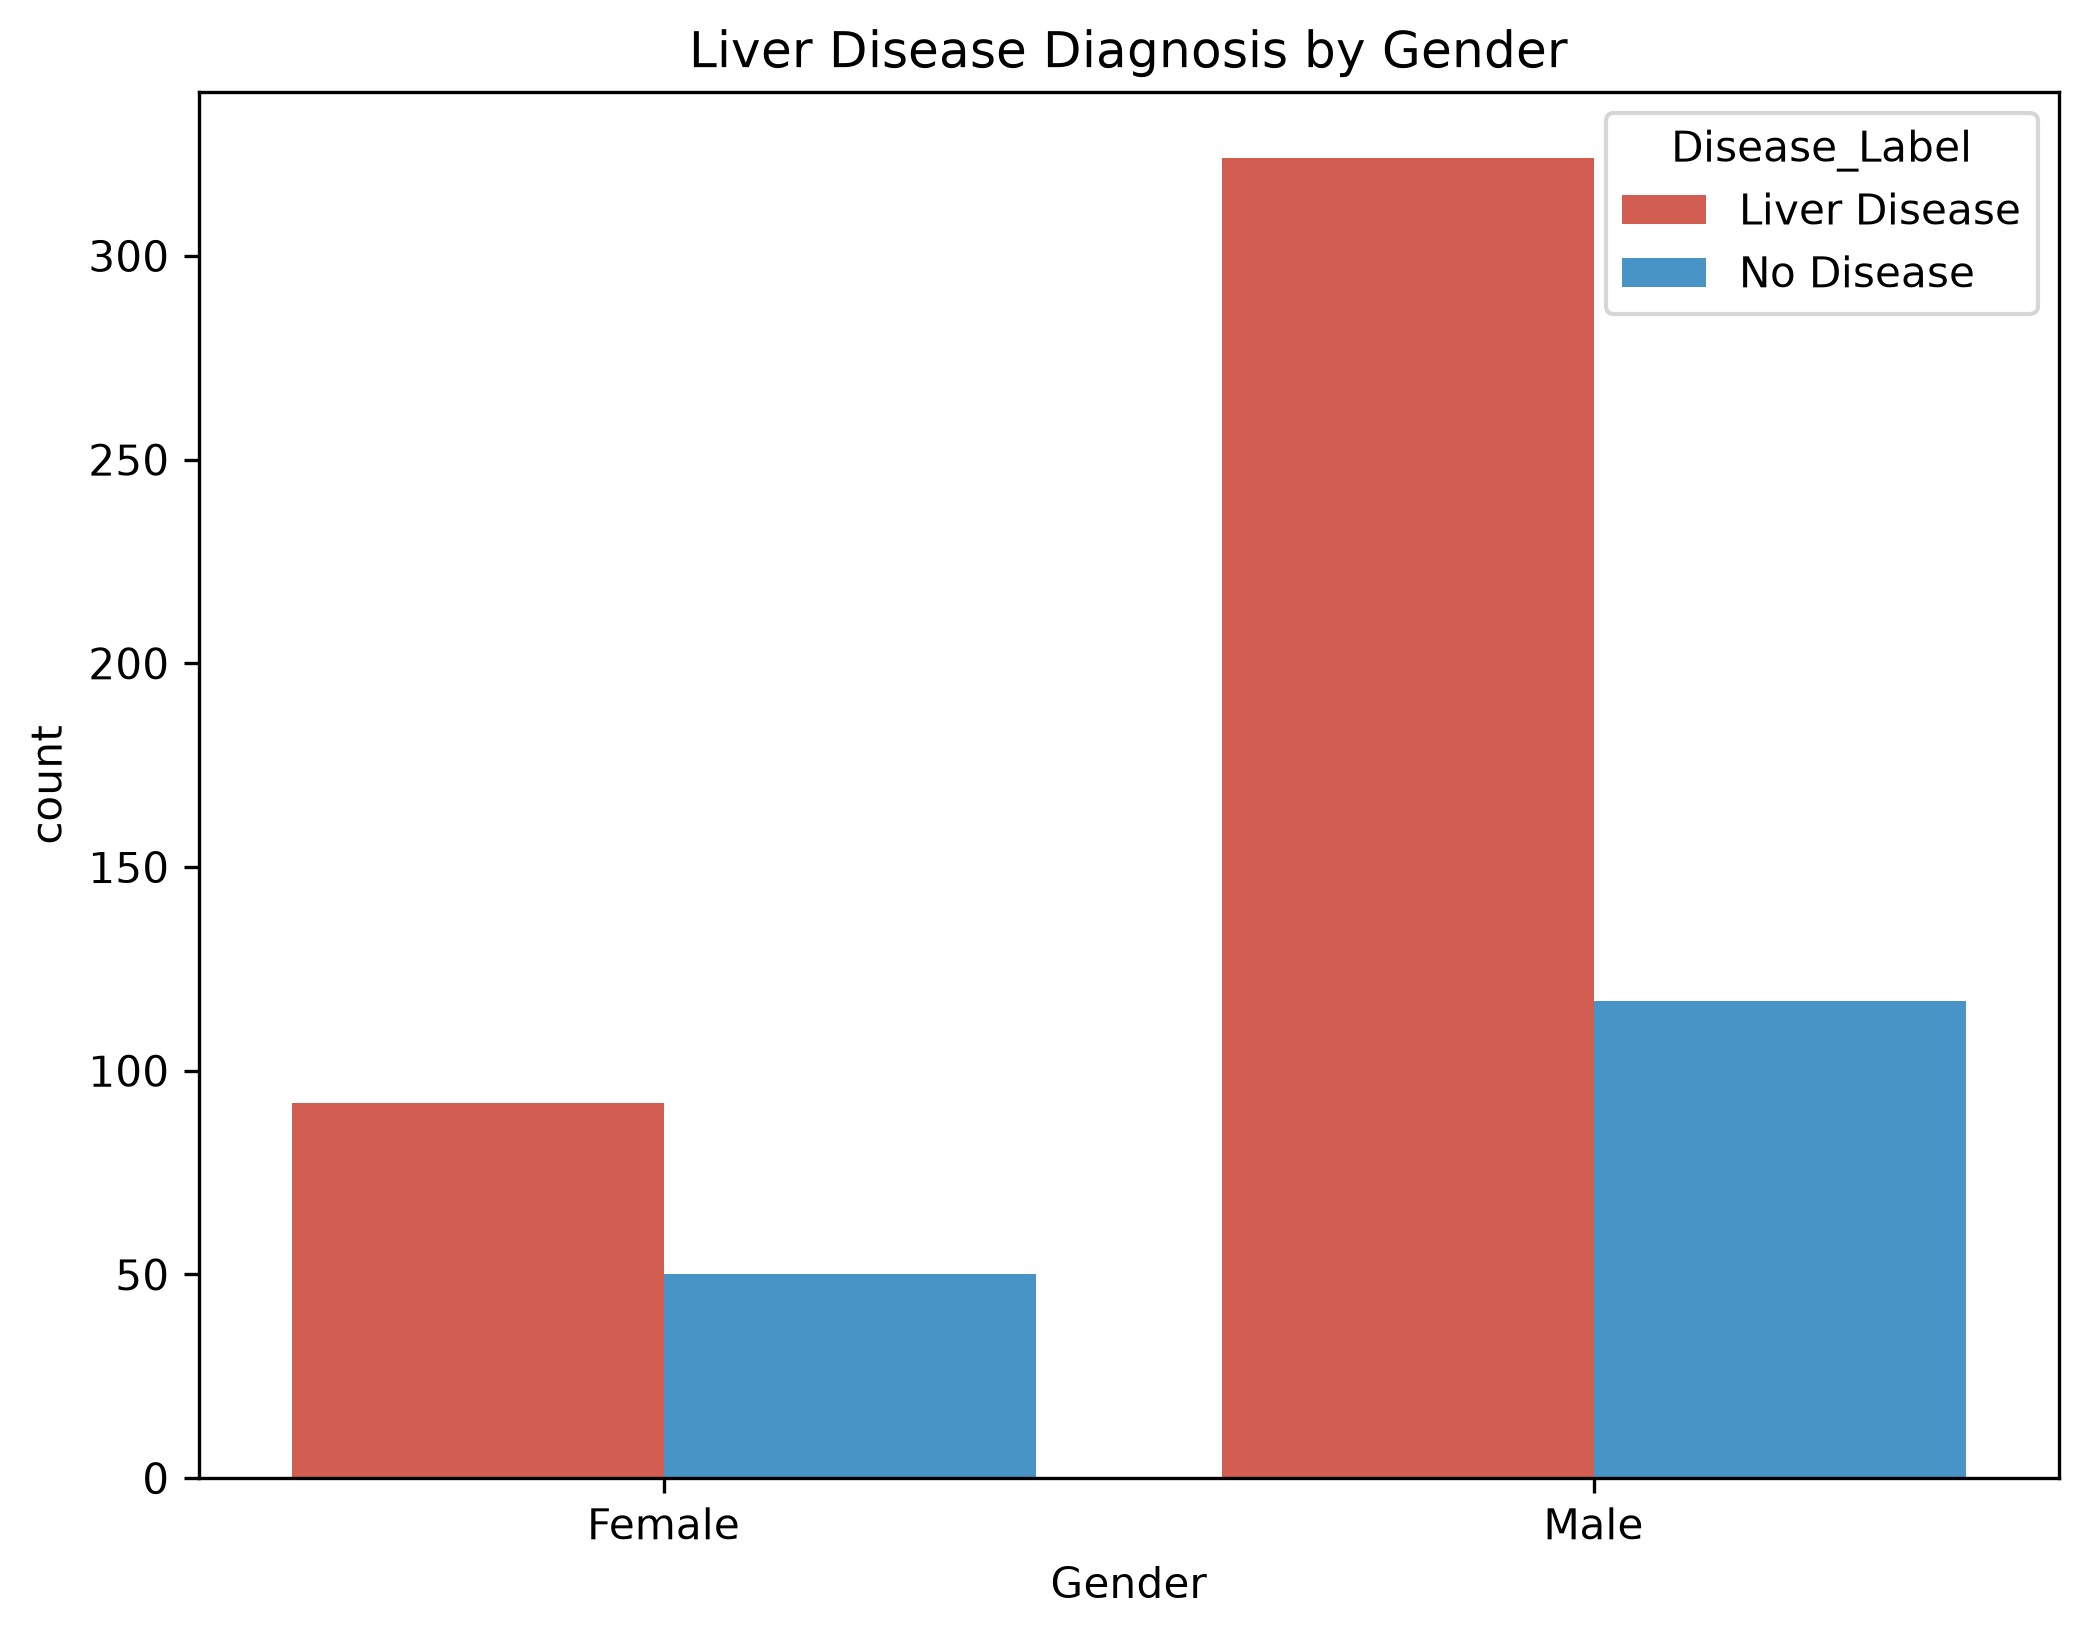

Saved outputs/figures/gender_disease_bar.png


In [7]:
# Chart 2: Gender vs Disease Count Bar Chart
plt.figure(figsize=(8, 6))
palette = {'Liver Disease': '#e74c3c', 'No Disease': '#3498db'}

ax = sns.countplot(data=df, x='Gender', hue='Disease_Label', palette=palette)
plt.title('Liver Disease Diagnosis by Gender', fontsize=14, weight='bold', pad=15)
plt.xlabel('Gender', fontsize=12, weight='bold')
plt.ylabel('Number of Patients', fontsize=12, weight='bold')
plt.legend(title='Condition', fontsize=11, title_fontsize='11')

# Add value labels on bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=11, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig('outputs/figures/gender_disease_bar.png', dpi=300)
plt.show()
print("Saved outputs/figures/gender_disease_bar.png")


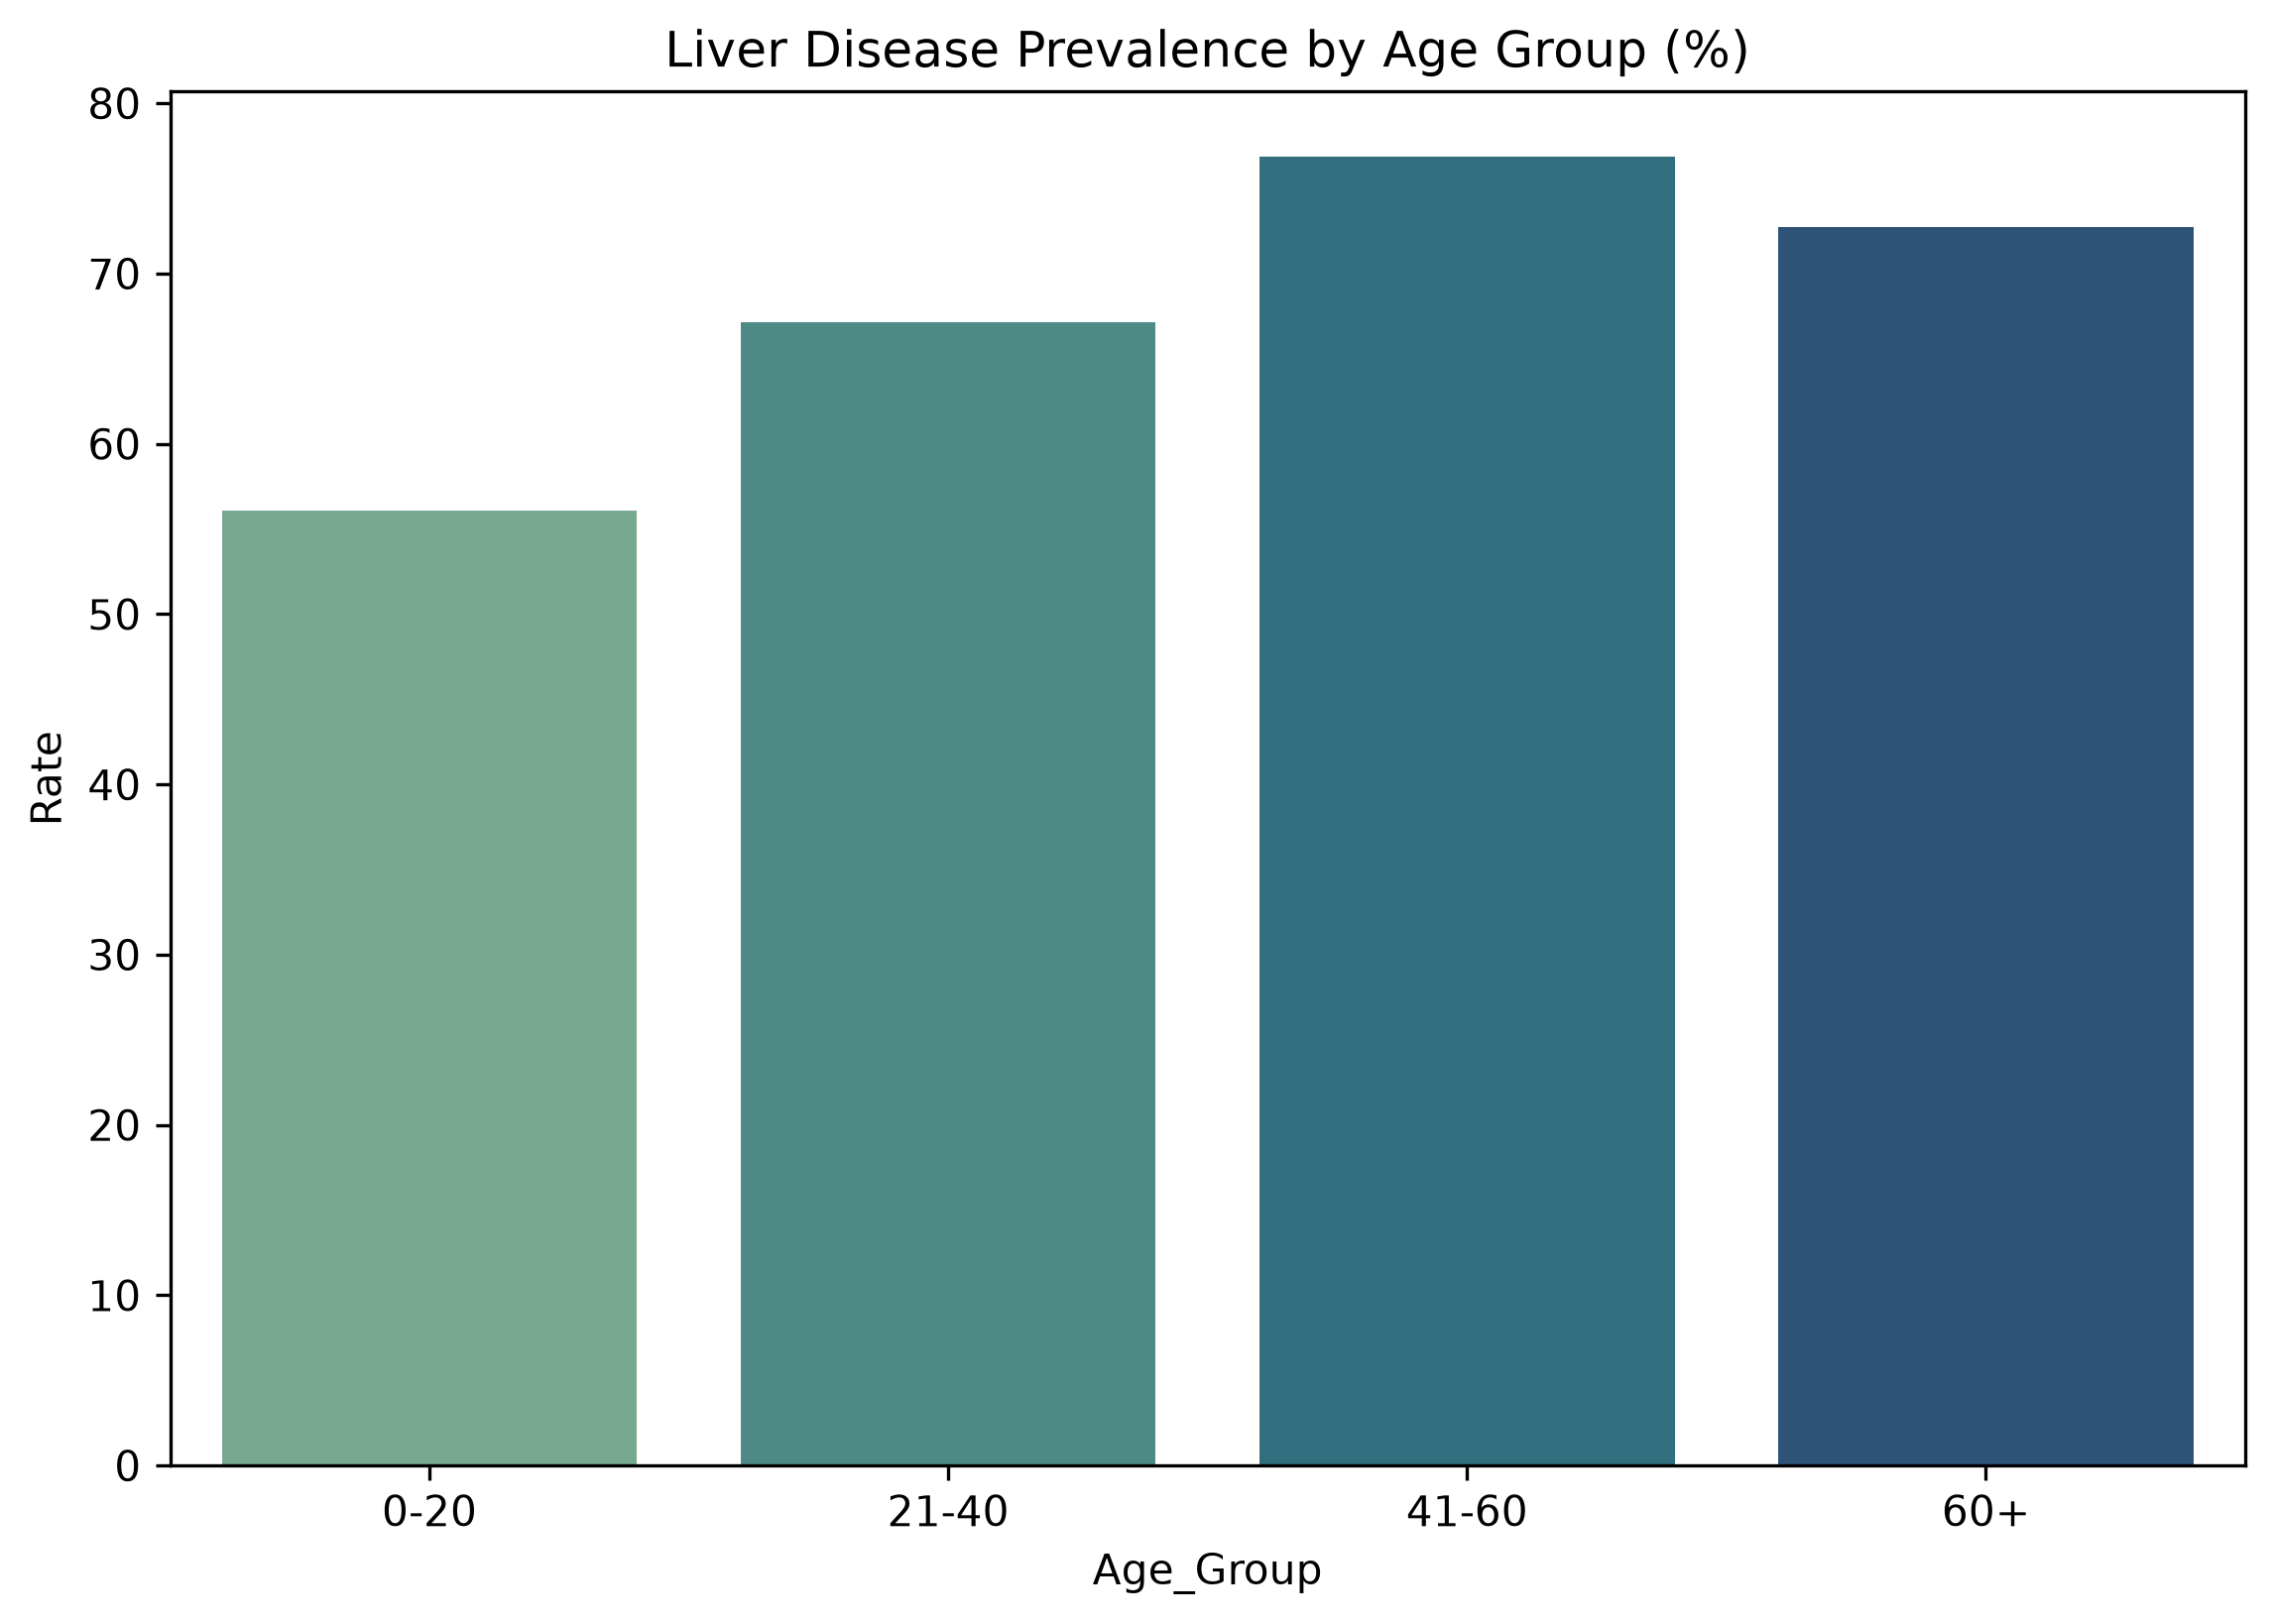

Saved outputs/figures/agegroup_disease_percent.png


In [8]:
# Chart 3: Age Group Disease Percentage Bar Chart
plt.figure(figsize=(9, 6))
age_pct = age_summary.reset_index()

ax = sns.barplot(data=age_pct, x='Age_Group', y='Disease_Rate_%', palette='crest')
plt.title('Liver Disease Prevalence by Age Group (%)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Age Group (Years)', fontsize=12, weight='bold')
plt.ylabel('Disease Prevalence (%)', fontsize=12, weight='bold')
plt.ylim(0, 100)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.savefig('outputs/figures/agegroup_disease_percent.png', dpi=300)
plt.show()
print("Saved outputs/figures/agegroup_disease_percent.png")


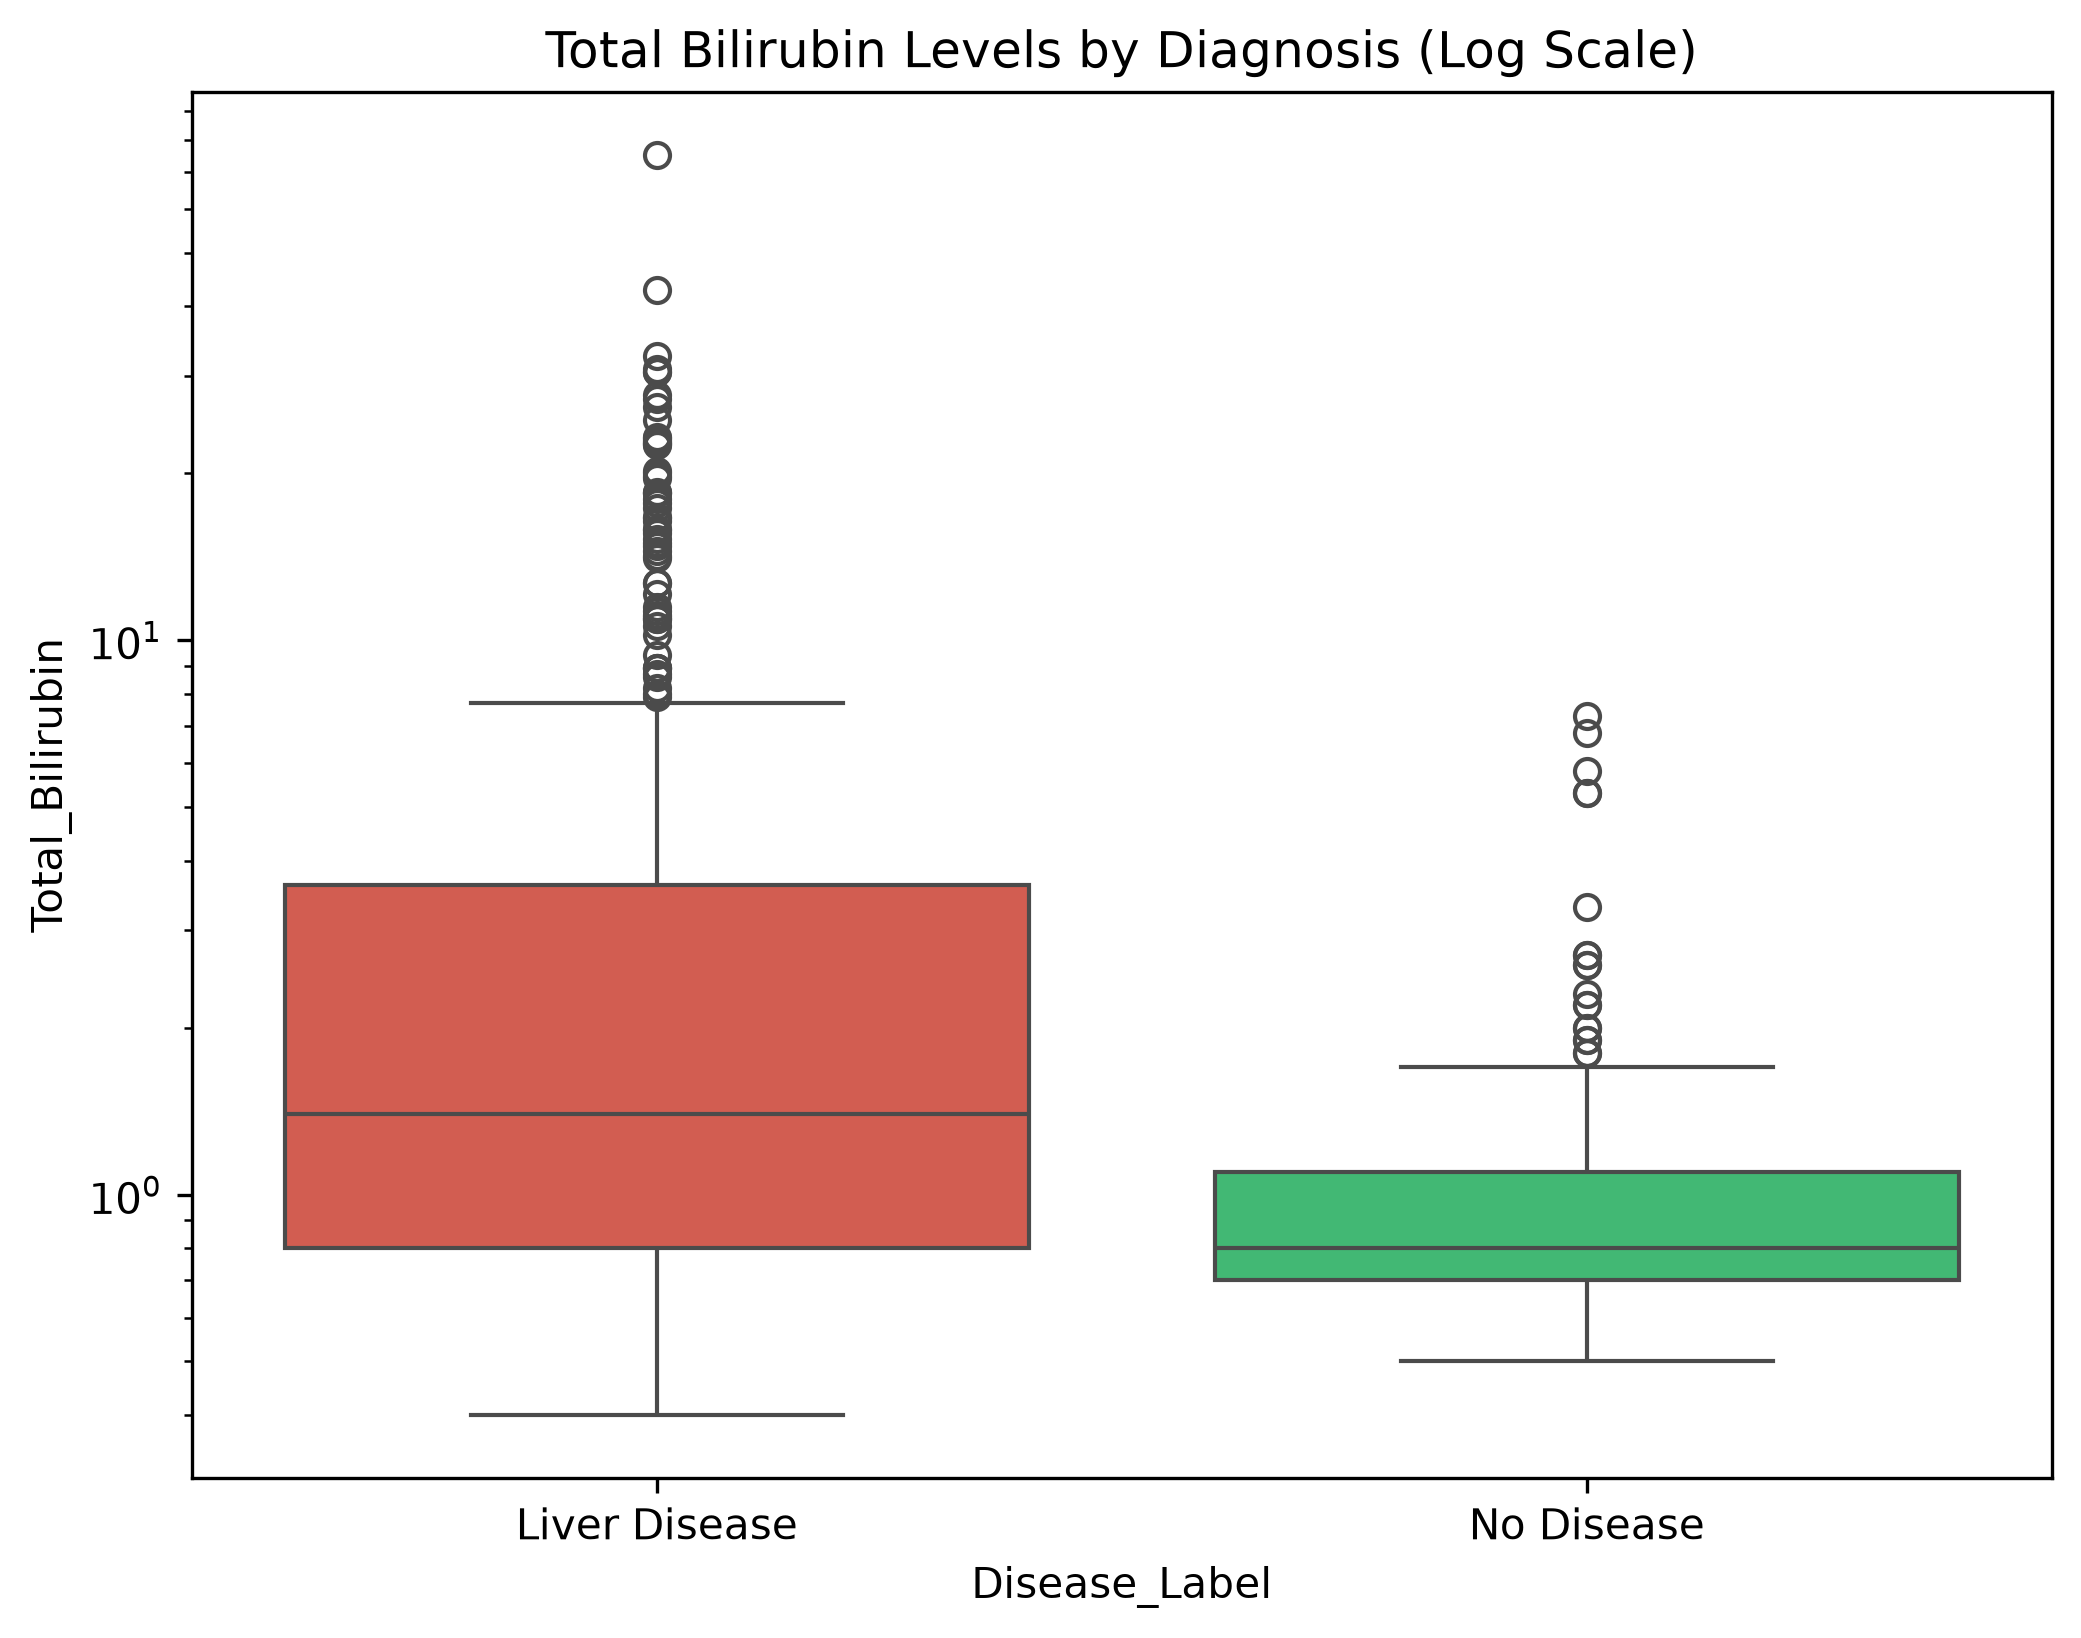

Saved outputs/figures/bilirubin_boxplot.png


In [9]:
# Chart 4: Total Bilirubin Distribution Boxplot (by Disease status)
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Disease_Label', y='Total_Bilirubin', palette={'Liver Disease': '#e74c3c', 'No Disease': '#2ecc71'}, showmeans=True)
plt.title('Total Bilirubin Levels by Diagnosis (Log Scale)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Diagnosis', fontsize=12, weight='bold')
plt.ylabel('Total Bilirubin (mg/dL) - Log Scale', fontsize=12, weight='bold')
plt.yscale('log')

plt.tight_layout()
plt.savefig('outputs/figures/bilirubin_boxplot.png', dpi=300)
plt.show()
print("Saved outputs/figures/bilirubin_boxplot.png")


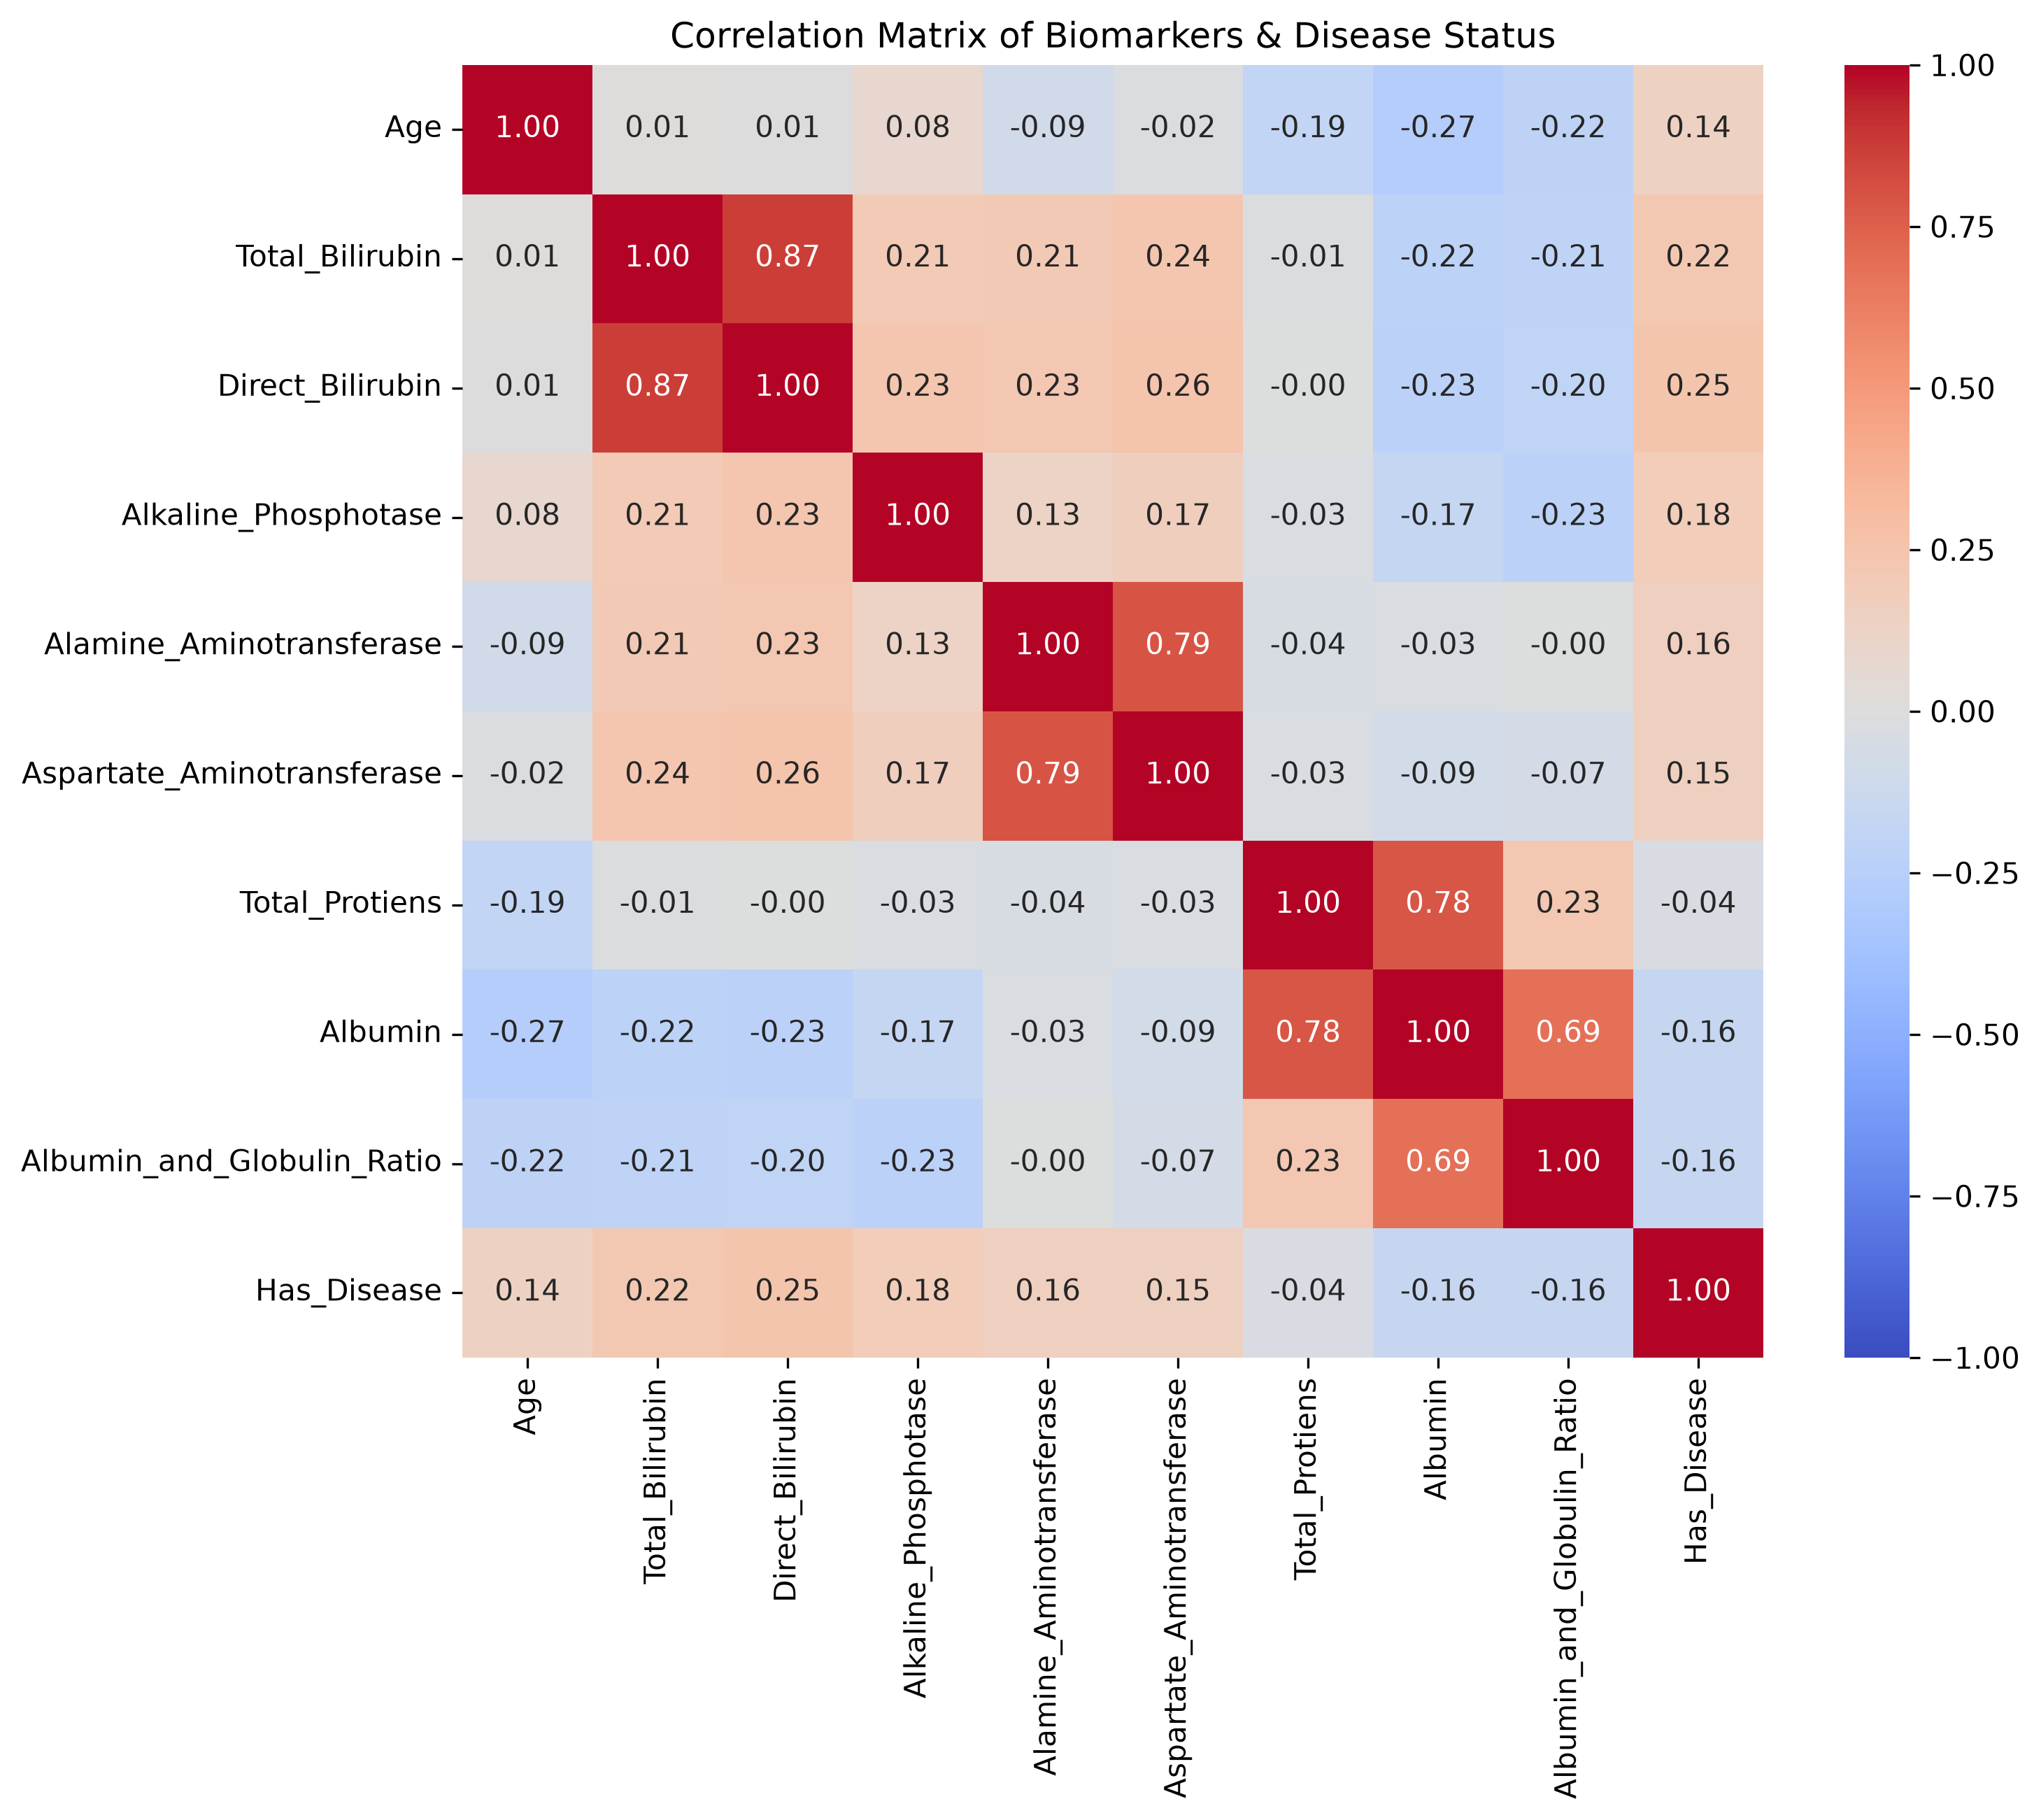

Saved outputs/figures/correlation_heatmap.png


In [10]:
# Chart 5: Correlation Heatmap of Numeric Features
plt.figure(figsize=(10, 8))
numeric_cols = [
    'Age', 'Total_Bilirubin', 'Direct_Bilirubin', 
    'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 
    'Aspartate_Aminotransferase', 'Total_Protiens', 
    'Albumin', 'Albumin_and_Globulin_Ratio', 'Has_Disease'
]
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Correlation Matrix of Biomarkers & Disease Status', fontsize=14, weight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.savefig('outputs/figures/correlation_heatmap.png', dpi=300)
plt.show()
print("Saved outputs/figures/correlation_heatmap.png")


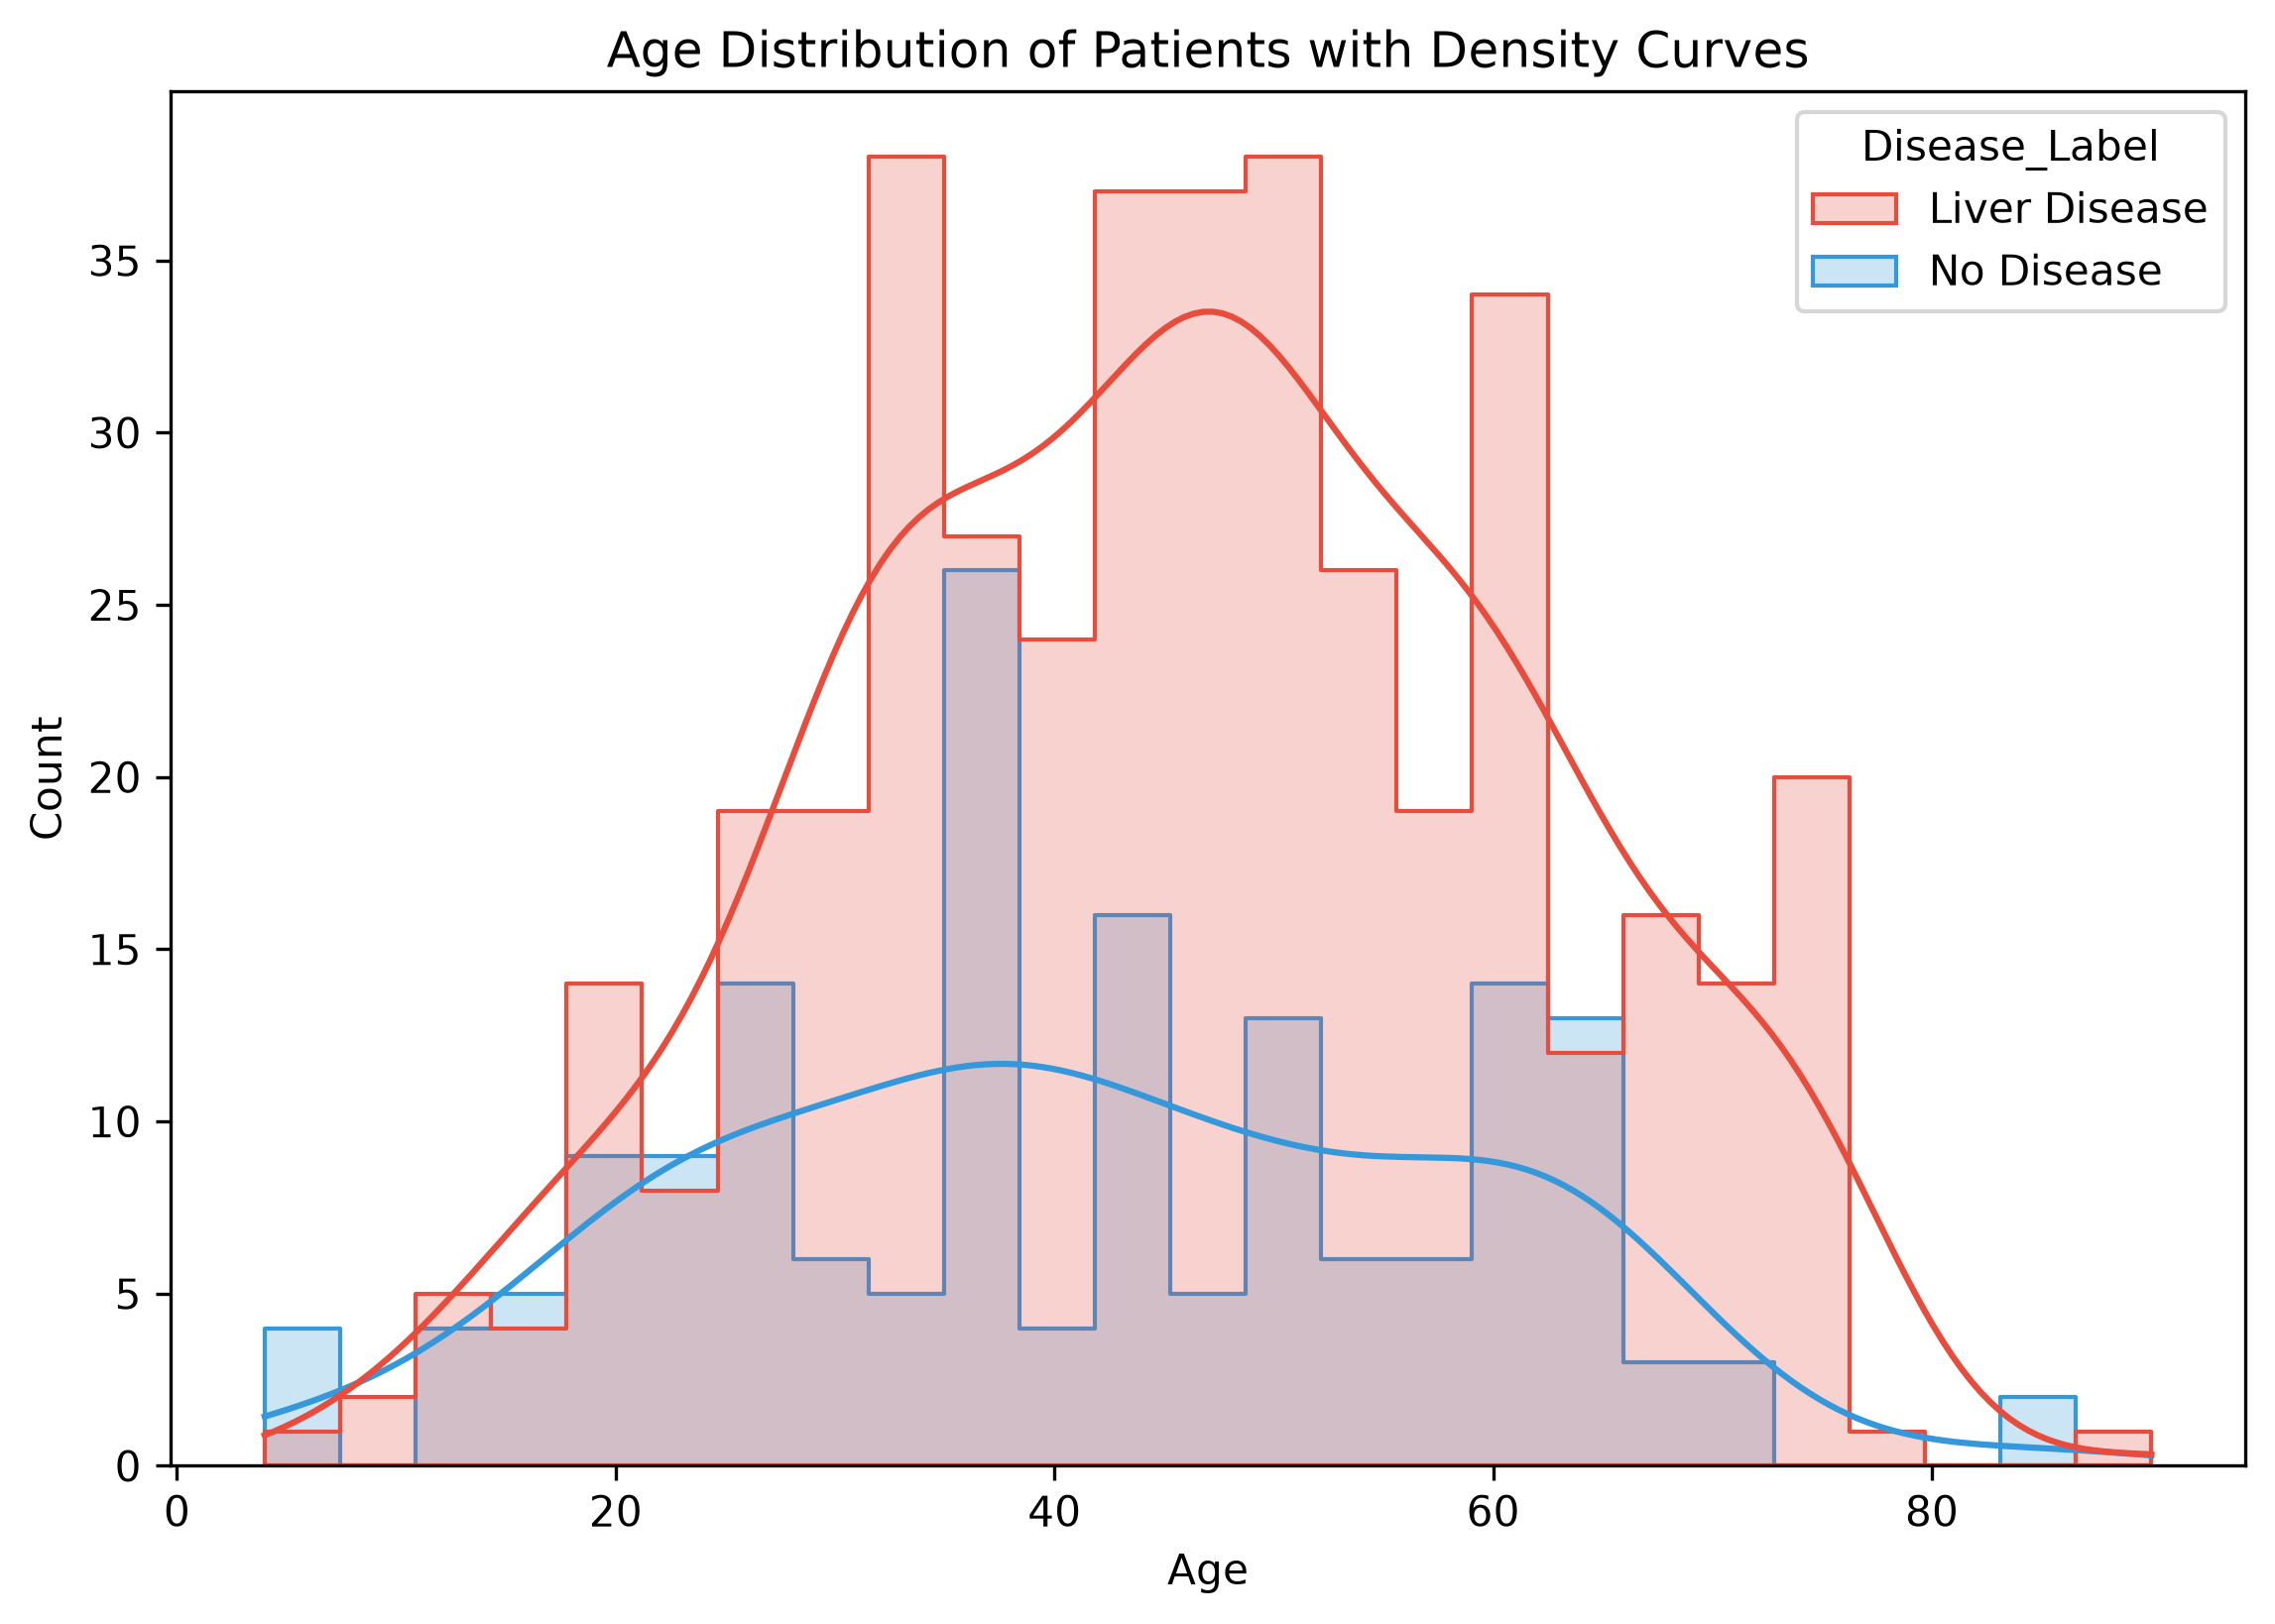

Saved outputs/figures/age_histogram.png


In [11]:
# Chart 6: Age Distribution Histogram with KDE
plt.figure(figsize=(9, 6))
sns.histplot(data=df, x='Age', hue='Disease_Label', kde=True, bins=25,
             palette={'Liver Disease': '#e74c3c', 'No Disease': '#3498db'}, element='step')
plt.title('Age Distribution of Patients with Density Curves', fontsize=14, weight='bold', pad=15)
plt.xlabel('Patient Age (Years)', fontsize=12, weight='bold')
plt.ylabel('Patient Count', fontsize=12, weight='bold')

plt.tight_layout()
plt.savefig('outputs/figures/age_histogram.png', dpi=300)
plt.show()
print("Saved outputs/figures/age_histogram.png")


In [12]:
# Step 6: Data-Driven Key Insights (Calculated directly from actual ILPD data)

avg_age_disease = df[df['Dataset'] == 1]['Age'].mean()
avg_age_nodisease = df[df['Dataset'] == 2]['Age'].mean()
male_disease_pct = gender_summary.loc['Male', 'Disease_Rate_%']
female_disease_pct = gender_summary.loc['Female', 'Disease_Rate_%']
highest_risk_age_group = age_summary['Disease_Rate_%'].idxmax()
highest_risk_age_val = age_summary['Disease_Rate_%'].max()
corr_bili = df['Total_Bilirubin'].corr(df['Direct_Bilirubin'])
corr_enzymes = df['Alamine_Aminotransferase'].corr(df['Aspartate_Aminotransferase'])
mean_bili_disease = df[df['Dataset'] == 1]['Total_Bilirubin'].mean()
mean_bili_healthy = df[df['Dataset'] == 2]['Total_Bilirubin'].mean()

insights = [
    f"1. Disease Prevalence: Out of 583 patients, {disease_count} ({disease_pct:.2f}%) are diagnosed with liver disease, while {no_disease_count} ({no_disease_pct:.2f}%) have no liver disease.",
    f"2. Gender Disparity: Male patients represent the majority ({gender_summary.loc['Male', 'Total_Patients']} of 583). Men have a {male_disease_pct:.2f}% disease rate compared to {female_disease_pct:.2f}% in females.",
    f"3. High-Risk Age Demographics: The highest liver disease prevalence occurs in the {highest_risk_age_group} age group at {highest_risk_age_val:.2f}%. Patients with liver disease average {avg_age_disease:.1f} years compared to {avg_age_nodisease:.1f} years for healthy individuals.",
    f"4. Bilirubin Elevation: Patients with liver disease have significantly higher Total Bilirubin (mean {mean_bili_disease:.2f} mg/dL) than healthy individuals (mean {mean_bili_healthy:.2f} mg/dL).",
    f"5. Biomarker Multi-collinearity: Total Bilirubin and Direct Bilirubin show an extremely high linear correlation (r = {corr_bili:.2f}), and transaminase enzymes (Alamine & Aspartate) exhibit strong co-elevation (r = {corr_enzymes:.2f})."
]

print("=== CALCULATED DATA INSIGHTS ===")
for insight in insights:
    print(insight)


=== CALCULATED DATA INSIGHTS ===
1. Disease Prevalence: Out of 583 patients, 416 (71.36%) are diagnosed with liver disease, while 167 (28.64%) have no liver disease.
2. Gender Disparity: Male patients represent the majority (441 of 583). Men have a 73.47% disease rate compared to 64.79% in females.
3. High-Risk Age Demographics: The highest liver disease prevalence occurs in the 41-60 age group at 74.29%. Patients with liver disease average 46.1 years compared to 41.2 years for healthy individuals.
4. Bilirubin Elevation: Patients with liver disease have significantly higher Total Bilirubin (mean 4.16 mg/dL) than healthy individuals (mean 1.14 mg/dL).
5. Biomarker Multi-collinearity: Total Bilirubin and Direct Bilirubin show an extremely high linear correlation (r = 0.87), and transaminase enzymes (Alamine & Aspartate) exhibit strong co-elevation (r = 0.79).


In [13]:
# Step 7: Export Cleaned CSV and Excel Workbook

# 1. Export Cleaned CSV
csv_export_path = 'data/processed/liver_cleaned.csv'
export_cols = [
    'Age', 'Age_Group', 'Gender', 'Gender_Code', 
    'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 
    'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 
    'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio', 
    'Dataset', 'Disease_Label', 'Has_Disease'
]
df[export_cols].to_csv(csv_export_path, index=False)
print(f"Exported cleaned CSV to: {csv_export_path}")

# 2. Prepare Summaries for Excel
disease_summary_df = pd.DataFrame({
    'Metric': ['Total Patients', 'Liver Disease Patients', 'No Disease Patients', 'Disease Prevalence (%)'],
    'Value': [total_patients, disease_count, no_disease_count, round(disease_pct, 2)]
})

gender_summary_export = gender_summary.reset_index()
age_summary_export = age_summary.reset_index()

# 3. Export Multi-Sheet Excel Workbook using openpyxl
excel_export_path = 'data/processed/liver_validation.xlsx'
with pd.ExcelWriter(excel_export_path, engine='openpyxl') as writer:
    df[export_cols].to_excel(writer, sheet_name='Cleaned Data', index=False)
    disease_summary_df.to_excel(writer, sheet_name='Disease Summary', index=False)
    gender_summary_export.to_excel(writer, sheet_name='Gender Summary', index=False)
    age_summary_export.to_excel(writer, sheet_name='Age Summary', index=False)

print(f"Exported multi-sheet Excel workbook to: {excel_export_path}")
print("Sheets included: 'Cleaned Data', 'Disease Summary', 'Gender Summary', 'Age Summary'")


Exported cleaned CSV to: data/processed/liver_cleaned.csv
Exported multi-sheet Excel workbook to: data/processed/liver_validation.xlsx
Sheets included: 'Cleaned Data', 'Disease Summary', 'Gender Summary', 'Age Summary'
